## CSP model assesment
The goal of this notebook is to test the CSP module and it's effeciveness on some artificial data, to verify the correctness.

In [1]:
# global variables to define the magnitude of the problem

NUM_TIMESLOT = 100         # divide the 24h horizon in NUM_TIMESLOTS chuncks
NUM_ANTENNA = 8            # number of ground antennas
NUM_SATELLITES = 1_000     # number of satellites in orbit

RND_SEED = 123              # setting random seed
import numpy.random as rnd
import random as pyrnd
rnd.seed(RND_SEED)
pyrnd.seed(RND_SEED)

# TODO: review the data generation once we have an idea for the dataset
AVG_NUM_WIN = 3             # average vsibility window size (in  number of timeslots) of a satellite
AVG_WIND_SIZE = 3           # avreage 
VAR_WIND_SIZE = 2           #
AVG_SERVING_ANTENNAS = 1    #

OVERLAPING_RATIO = 0.7      # ratio of how much the visibility slot should overlap

In [2]:
# ----- data generation function -----

import sys
sys.path.insert(0, '../src/')
from CSP import CSP, Var, Timeslot


def generate_data(
        num_sat :int,
        num_antenna :int,
        avg_windows :int,
        avg_window_size :int,
        var_window_size :int,
        num_timeslot :int,
        avg_serving_ant_per_sat :int,
) -> CSP:
    csp = CSP(max_vars=num_sat)

    for sat in range(num_sat):
        v = Var(id=sat)

        v.domain = set()

        num_wind: int = 0
        while num_wind == 0: num_wind = rnd.poisson(lam=avg_windows)

        wind_size        = [0  for _ in range(num_wind)]
        wind_placement   = [_  for _ in range(num_wind)]
        serving_antennas = [[] for _ in range(num_wind)]

        for w in range(num_wind):
            while wind_size[w] <= 0: wind_size[w] = int(rnd.normal(loc=avg_window_size, scale=var_window_size))

            overlap_candidate = None
            if not rnd.uniform(0, 1) < OVERLAPING_RATIO:
                wind_placement[w] = rnd.randint(low=0, high=num_timeslot - wind_size[w], size=None)
            elif len(csp.vars) > 0:
                overlap_candidate = pyrnd.sample(list(pyrnd.sample(csp.vars, k=1)[0].domain), k=1)[0]
                wind_placement[w] = overlap_candidate.timeframe

            while any(wind_placement[w] < wind_placement[i] + wind_size[i]
                        and wind_placement[w] + wind_size[w] > wind_placement[i]
                        for i in range(w)):
                wind_placement[w] = rnd.randint(low=0, high=num_timeslot - wind_size[w], size=None)


            num_serving_antenna: int = 0
            while num_serving_antenna == 0:
                num_serving_antenna = rnd.poisson(lam=avg_serving_ant_per_sat)
            if wind_size[w] == 1: num_serving_antenna += 1      # making insolvable problems mroe rare
            num_serving_antenna = min(num_serving_antenna, num_antenna) 
            serving_antennas[w] = pyrnd.sample(population=list(range(num_antenna)), k=num_serving_antenna)
            if overlap_candidate is not None:
                serving_antennas[w] += [overlap_candidate.antenna_id]

            for slot in range(wind_size[w]):
                for ant in serving_antennas[w]:
                    v.domain.add(Timeslot(antenna_id=ant, timeframe=wind_placement[w] + slot))

        csp.add_var(v)

    csp.update_constrains()
    return csp

# todo: find a way to improve constraint density


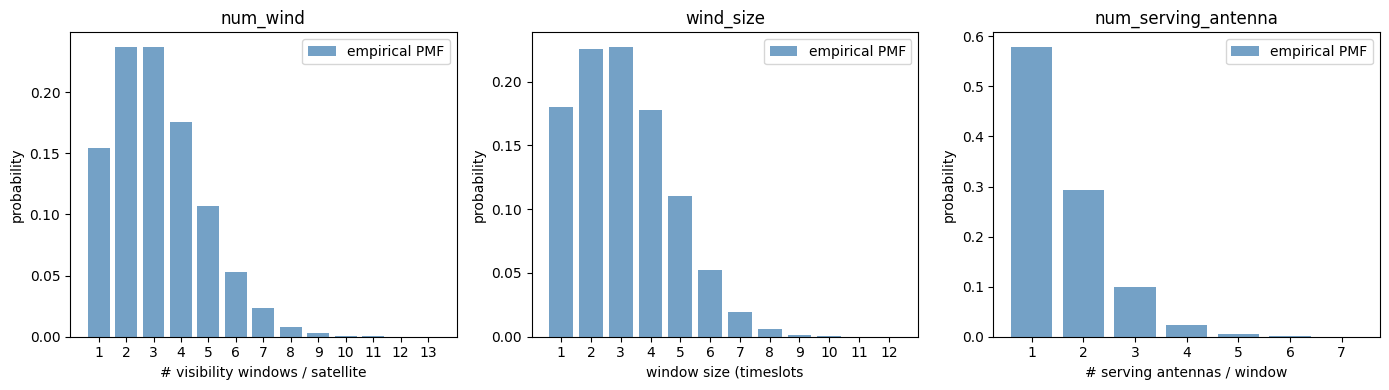

In [3]:
# show the probability distributions used to generate the data

import matplotlib.pyplot as plt
import numpy as np
import numpy.random as rnd_plot

N_SAMPLES = 100_000
rng = rnd_plot.default_rng(RND_SEED)

# --- num_wind: Poisson(AVG_NUM_WIN), excluding 0 ---
num_wind_samples = rng.poisson(lam=AVG_NUM_WIN, size=N_SAMPLES)
num_wind_samples = num_wind_samples[num_wind_samples > 0]

# --- wind_size: Normal(AVG_WIND_SIZE, VAR_WIND_SIZE), truncated to int > 0 ---
wind_size_samples = rng.normal(loc=AVG_WIND_SIZE, scale=VAR_WIND_SIZE, size=N_SAMPLES).astype(int)
wind_size_samples = wind_size_samples[wind_size_samples > 0]

# --- num_serving_antenna: Poisson(AVG_SERVING_ANTENNAS), excluding 0, capped at NUM_ANTENNA ---
num_ant_samples = rng.poisson(lam=AVG_SERVING_ANTENNAS, size=N_SAMPLES)
num_ant_samples = num_ant_samples[num_ant_samples > 0]
num_ant_samples = np.clip(num_ant_samples, 1, NUM_ANTENNA)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, data, title, xlabel, discrete in [
    (axes[0], num_wind_samples,  "num_wind",             "# visibility windows / satellite", True),
    (axes[1], wind_size_samples, "wind_size",            "window size (timeslots"          , True),
    (axes[2], num_ant_samples,   "num_serving_antenna",  "# serving antennas / window"     , True),
]:
    bins = np.arange(data.min(), data.max() + 2) - 0.5
    counts, edges = np.histogram(data, bins=bins, density=True)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.bar(centers, counts, width=0.8, color="steelblue", alpha=0.75, label="empirical PMF")
    ax.set_xticks(np.arange(data.min(), data.max() + 1))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("probability")
    ax.legend()

plt.tight_layout()
plt.show()


## CSP instance generation

In [4]:
# ----- CSP instance generation -----
csp :CSP = generate_data(NUM_SATELLITES, 
                         NUM_ANTENNA,
                         AVG_NUM_WIN,
                         AVG_WIND_SIZE,
                         VAR_WIND_SIZE,
                         NUM_TIMESLOT,
                         AVG_SERVING_ANTENNAS
                        )
from pprint import pprint
pprint(csp.compute_summary())

{'avg_degree': 244.958,
 'avg_domain_size': 21.365,
 'const_dens': 0.2452032032032032,
 'max_domain_size': 83.0,
 'min_domain_size': 2.0,
 'num_const': 122479,
 'num_vars': 1000,
 'sd_degree': 118.46389422942333,
 'sd_domain_size': 13.437104412781794}


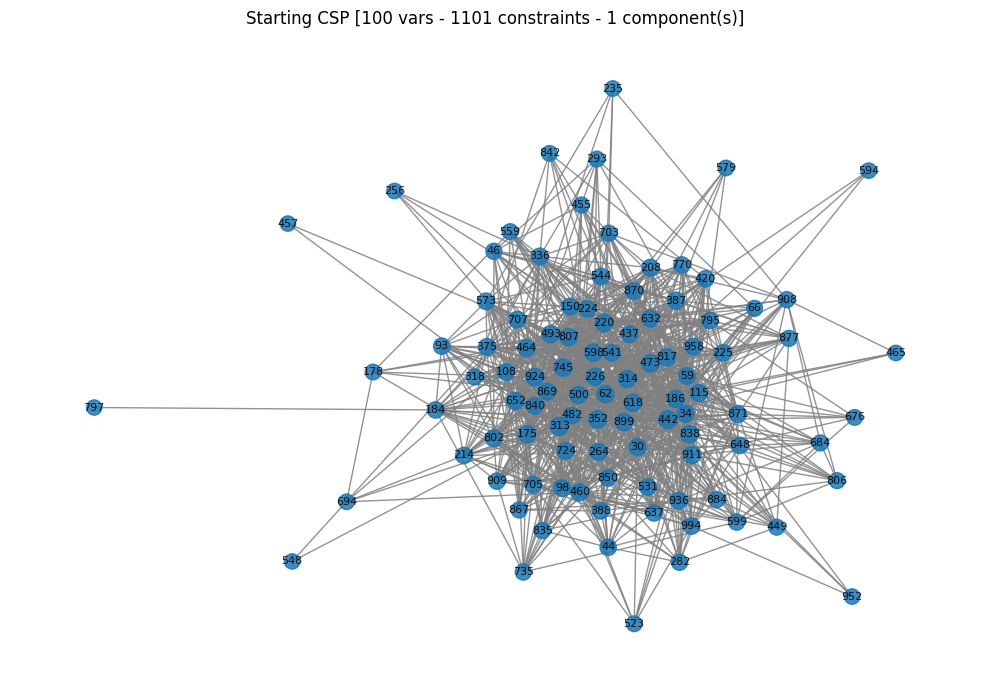

In [20]:
# ----- constraint graph plotting -----

import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def plot_constraint_graph(csp, title: str, max_nodes=None, seed=42) -> None:
    """
    Draw the constraint graph of a CSP.
    Each node is a variable (sized by degree), edges are constraints,
    and nodes are colored by connected component.
    Pass max_nodes to subsample large CSPs.
    """
    # if the number of nores to plot is specified, pick the variables to plot randomly
    vars_to_plot = csp.vars if max_nodes is None else pyrnd.sample(csp.vars, max_nodes)

    # creating plotting graph
    G = nx.Graph()
    G.add_nodes_from(v.id for v in vars_to_plot)
    for v in vars_to_plot:
        for u in vars_to_plot:
            if u.id > v.id and csp.constraint_exists(v, u):
                G.add_edge(v.id, u.id)

    # picking a color for each CC
    components = list(nx.connected_components(G))
    cmap = plt.colormaps["tab10"]
    node_color = {}
    for i, comp in enumerate(components):
        color = cmap(i % 10)
        for node in comp:
            node_color[node] = color

    colors = [node_color[n] for n in G.nodes()]
    sizes  = [120 + G.degree(n) for n in G.nodes()]

    # plot the constraint graph
    fig, ax = plt.subplots(figsize=(10, 7))
    pos = nx.spring_layout(G, seed=seed)
    nx.draw_networkx(
        G, pos, ax=ax,
        node_color=colors, node_size=sizes,
        with_labels=True, font_size=8,
        edge_color="gray", alpha=0.85,
    )
    ax.set_title(
        f"{title} [{G.number_of_nodes()} vars - {G.number_of_edges()} constraints - {len(components)} component(s)]"
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()

plot_constraint_graph(csp, title="Starting CSP", max_nodes=100)

In [ ]:
from pprint import pprint
print("before preprocessing")
pprint(csp.compute_summary())

from CSP import split_connected_components
cc_csp = split_connected_components(csp)
print(f"\nprinting cc before preprocessing we got {len(cc_csp)}")
for cc in cc_csp:   
    pprint(cc.compute_summary())


from CSP import ac3
ac3(csp)
print("\nAfter preprocessing (whole problem)")
pprint(csp.compute_summary())

cc_csp = split_connected_components(csp)
print(f"\nPrinting cc after preprocessing we got {len(cc_csp)}")
for cc in cc_csp:   
    pprint(cc.compute_summary())


before preprocessing
{'avg_degree': 143.3186,
 'avg_domain_size': 18.6093,
 'const_dens': 0.014333293329332933,
 'max_domain_size': 93,
 'min_domain_size': 2,
 'num_const': 716593,
 'num_vars': 10000}

printing cc before preprocessing we got 1
{'avg_degree': 143.3186,
 'avg_domain_size': 18.6093,
 'const_dens': 0.014333293329332933,
 'max_domain_size': 93,
 'min_domain_size': 2,
 'num_const': 716593,
 'num_vars': 10000}

After preprocessing (whole problem)
{'avg_degree': 143.3186,
 'avg_domain_size': 18.6093,
 'const_dens': 0.014333293329332933,
 'max_domain_size': 93,
 'min_domain_size': 2,
 'num_const': 716593,
 'num_vars': 10000}

Printing cc after preprocessing we got 1
{'avg_degree': 143.3186,
 'avg_domain_size': 18.6093,
 'const_dens': 0.014333293329332933,
 'max_domain_size': 93,
 'min_domain_size': 2,
 'num_const': 716593,
 'num_vars': 10000}


In [ ]:
# ── Unit test: split_connected_components ────────────────────────────────────
#
# Hand-crafted CSP with 3 known components:
#
#   Component A (chain):  0 ─── 1 ─── 2
#   Component B (edge):   3 ─── 4
#   Component C (solo):   5
#
# Overlapping domains create constraints; distinct antenna ids per component
# guarantee zero cross-component domain overlap by construction.

from CSP import CSP, Var, Timeslot, split_connected_components
import numpy as np

MAX_VARS = 6
csp_test = CSP(max_vars=MAX_VARS)

domains = {
    0: {Timeslot(0, 0), Timeslot(0, 1)},   # shares (0,1) with 1
    1: {Timeslot(0, 1), Timeslot(0, 2)},   # shares (0,2) with 2
    2: {Timeslot(0, 2), Timeslot(0, 3)},   # end of chain A
    3: {Timeslot(1, 0), Timeslot(1, 1)},   # shares (1,1) with 4
    4: {Timeslot(1, 1), Timeslot(1, 2)},   # end of edge B
    5: {Timeslot(2, 0)},                   # isolated
}

for var_id, dom in domains.items():
    v = Var(id=var_id)
    v.domain = dom
    csp_test.add_var(v)

csp_test.update_constrains()

print("Constraint matrix (6x6 upper-triangular):")
print(csp_test.const[:MAX_VARS, :MAX_VARS].astype(int))
print()

# ── expected ──────────────────────────────────────────────────────────────────
EXPECTED = [
    {"ids": {0, 1, 2}, "num_const": 2},   # chain → 2 edges
    {"ids": {3, 4},    "num_const": 1},   # single edge
    {"ids": {5},       "num_const": 0},   # isolated
]

components = split_connected_components(csp_test)
# sort by smallest var id for deterministic comparison
components.sort(key=lambda c: min(v.id for v in c.vars))

assert len(components) == len(EXPECTED), \
    f"Expected {len(EXPECTED)} components, got {len(components)}"

all_ok = True
for i, (sub, exp) in enumerate(zip(components, EXPECTED)):
    ids = {v.id for v in sub.vars}
    nc  = sub.num_constraints()
    ok  = ids == exp["ids"] and nc == exp["num_const"]
    if not ok:
        all_ok = False
    status = "OK  " if ok else "FAIL"
    print(f"Component {i}  [{status}]  "
          f"vars={str(sorted(ids)):<14}  constraints={nc}  "
          f"(expected vars={sorted(exp['ids'])}, constraints={exp['num_const']})")

    # verify no constraint entry leaks to variables outside this component
    other_ids = {v.id for c in components if c is not sub for v in c.vars}
    for v in sub.vars:
        for oid in other_ids:
            lo, hi = min(v.id, oid), max(v.id, oid)
            if sub.const[lo][hi]:
                print(f"  !! cross-component constraint leak : var {v.id} <-> var {oid}")
                all_ok = False

print()
print("All checks passed!" if all_ok else "SOME CHECKS FAILED.")

Constraint matrix (6x6 upper-triangular):
[[0 1 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 1 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]

Component 0  [OK  ]  vars=[0, 1, 2]       constraints=2  (expected vars=[0, 1, 2], constraints=2)
Component 1  [OK  ]  vars=[3, 4]          constraints=1  (expected vars=[3, 4], constraints=1)
Component 2  [OK  ]  vars=[5]             constraints=0  (expected vars=[5], constraints=0)

All checks passed!
